In [7]:
!pip install -q kagglehub
import kagglehub, os, shutil

path = kagglehub.dataset_download("dgawlik/nyse")
for f in os.listdir(path):
    if f.endswith(".csv"):
        shutil.copy(os.path.join(path, f), f"/content/{f}")

!wc -l /content/prices-split-adjusted.csv

Using Colab cache for faster access to the 'nyse' dataset.
851265 /content/prices-split-adjusted.csv


In [8]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score

df = pd.read_csv("prices-split-adjusted.csv", parse_dates=["date"])
df = df.sort_values(["symbol", "date"]).reset_index(drop=True)
df = df[(df[["open", "high", "low", "close"]] > 0).all(axis=1)].reset_index(drop=True)

for c in ["open", "high", "low", "close"]:
    df[f"log_{c}"] = np.log(df[c])
df["log_volume"] = np.log1p(df["volume"])

df["ret_0"] = df.groupby("symbol")["log_close"].diff()
for k in range(1, 5):
    df[f"ret_{k}"] = df.groupby("symbol")["ret_0"].shift(k)

for w in [5, 10]:
    ma = df.groupby("symbol")["close"].transform(lambda s: s.rolling(w).mean())
    df[f"dist_ma{w}"] = df["close"] / ma - 1

df["vol_10"] = df.groupby("symbol")["ret_0"].transform(lambda s: s.rolling(10).std())
df["target"] = df.groupby("symbol")["log_close"].shift(-1)

features = ["log_open", "log_high", "log_low", "log_close", "log_volume",
            "ret_0", "ret_1", "ret_2", "ret_3", "ret_4",
            "dist_ma5", "dist_ma10", "vol_10"]

df = df.dropna(subset=features + ["target"]).reset_index(drop=True)
# Après le calcul des variables par entreprise, trier globalement par date
# pour que les découpages temporels et TimeSeriesSplit respectent le temps.
df = df.sort_values(["date", "symbol"]).reset_index(drop=True)
print("Dataset final :", df.shape)

train = df[df["date"] < "2016-01-01"]
test = df[df["date"] >= "2016-01-01"]
print("Train :", train.shape, "|", train["date"].min().date(), "->", train["date"].max().date())
print("Test  :", test.shape, "|", test["date"].min().date(), "->", test["date"].max().date())

X_train, y_train = train[features].values, train["target"].values
X_test, y_test = test[features].values, test["target"].values
cur_train, cur_test = train["log_close"].values, test["log_close"].values

# Le scaler est ajusté uniquement sur la période d'entraînement effective (< 2015-07-01).
# Validation et test sont transformés avec les mêmes paramètres, sans fuite de données.
fit_mask = train["date"].values < np.datetime64("2015-07-01")
sx, sy = StandardScaler(), StandardScaler()
sx.fit(X_train[fit_mask])
sy.fit(y_train[fit_mask].reshape(-1, 1))
X_train_s = sx.transform(X_train)
X_test_s = sx.transform(X_test)
y_train_s = sy.transform(y_train.reshape(-1, 1)).ravel()
y_test_s = sy.transform(y_test.reshape(-1, 1)).ravel()

def evaluate(pred_log, y_log, cur_log, name="modèle"):
    r2 = r2_score(y_log, pred_log)
    rmse_usd = np.sqrt(np.mean((np.exp(pred_log) - np.exp(y_log)) ** 2))
    dir_acc = np.mean(np.sign(pred_log - cur_log) == np.sign(y_log - cur_log))
    print(f"{name:<28} R² = {r2:.5f} | RMSE = {rmse_usd:.3f} $ | Directional acc = {dir_acc:.3%}")
    return r2, rmse_usd, dir_acc

# Baseline naïve : le prix de demain est prédit égal au prix d'aujourd'hui.
naive_r2 = r2_score(y_test, cur_test)
naive_rmse = np.sqrt(np.mean((np.exp(cur_test) - np.exp(y_test)) ** 2))
print(f"Baseline naïve — R² = {naive_r2:.5f} | RMSE = {naive_rmse:.3f} $")
print(f"Baseline direction 'toujours hausse' : {np.mean(y_test > cur_test):.3%}")

Dataset final : (845753, 21)
Train : (720149, 21) | 2010-01-19 -> 2015-12-31
Test  : (125604, 21) | 2016-01-04 -> 2016-12-29
Baseline naïve — R² = 0.99934 | RMSE = 2.143 $
Baseline direction 'toujours hausse' : 52.353%


In [9]:
import torch
print(torch.cuda.is_available())

False


In [10]:
import os, copy, numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn
from sklearn.metrics import r2_score

os.makedirs("images", exist_ok=True)
device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(42); np.random.seed(42)
print("Device :", device)

# ---------- Train / Validation / Test (chronologique) ----------
d = train["date"].values
m_tr = d < np.datetime64("2015-07-01")
m_va = ~m_tr
print("Train :", m_tr.sum(), "| Validation :", m_va.sum(), "| Test :", len(X_test_s))

Xtr, ytr, ylog_tr, cur_tr = X_train_s[m_tr], y_train_s[m_tr], y_train[m_tr], cur_train[m_tr]
Xva, yva, ylog_va, cur_va = X_train_s[m_va], y_train_s[m_va], y_train[m_va], cur_train[m_va]

T = lambda a: torch.tensor(a, dtype=torch.float32, device=device)
Xtr_t, ytr_t = T(Xtr), T(ytr)
Xva_t, yva_t = T(Xva), T(yva)
Xte_t, yte_t = T(X_test_s), T(y_test_s)

sets = {"tr": (Xtr_t, ytr_t, ylog_tr, cur_tr),
        "va": (Xva_t, yva_t, ylog_va, cur_va)}
mu_y, sd_y = sy.mean_[0], sy.scale_[0]

# ---------- Architecture : MLP paramétrable ----------
class MLP(nn.Module):
    def __init__(self, n_in, hidden=(64, 32), dropout=0.0, batchnorm=False):
        super().__init__()
        layers, d_in = [], n_in
        for h in hidden:
            layers.append(nn.Linear(d_in, h))
            if batchnorm: layers.append(nn.BatchNorm1d(h))
            layers.append(nn.ReLU())
            if dropout > 0: layers.append(nn.Dropout(dropout))
            d_in = h
        layers.append(nn.Linear(d_in, 1))
        self.net = nn.Sequential(*layers)
    def forward(self, x):
        return self.net(x)

# ---------- Métriques : loss, R², directional accuracy ----------
def metrics(model, X, y_s, y_log, cur_log, loss_fn=nn.MSELoss()):
    model.eval()
    with torch.no_grad():
        p = model(X).squeeze(1)
        loss = loss_fn(p, y_s).item()
        p_log = p.cpu().numpy() * sd_y + mu_y
    r2 = r2_score(y_log, p_log)
    acc = np.mean(np.sign(p_log - cur_log) == np.sign(y_log - cur_log))
    return loss, r2, acc, p_log

# ---------- Entraînement ----------
OPTS = {"adam": torch.optim.Adam,
        "rmsprop": torch.optim.RMSprop,
        "sgd": lambda p, lr, weight_decay: torch.optim.SGD(p, lr=lr, momentum=0.9, weight_decay=weight_decay)}

def train_model(hidden=(64, 32), lr=1e-3, optimizer="adam", epochs=40, batch_size=1024,
                weight_decay=0.0, dropout=0.0, batchnorm=False, patience=None):
    torch.manual_seed(42)
    model = MLP(Xtr_t.shape[1], hidden, dropout, batchnorm).to(device)
    opt = OPTS[optimizer](model.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.MSELoss()
    hist = {f"{s}_{k}": [] for s in ["tr", "va"] for k in ["loss", "r2", "acc"]}
    best_val, best_state, best_ep, wait = np.inf, None, 0, 0
    n = len(Xtr_t)

    for ep in range(epochs):
        model.train()
        perm = torch.randperm(n, device=device)
        for i in range(0, n, batch_size):
            idx = perm[i:i + batch_size]
            if len(idx) < 2: continue
            opt.zero_grad()
            loss = loss_fn(model(Xtr_t[idx]).squeeze(1), ytr_t[idx])
            loss.backward()
            opt.step()

        for s, (X, y_s, y_log, cur) in sets.items():
            l, r2, acc, _ = metrics(model, X, y_s, y_log, cur)
            hist[f"{s}_loss"].append(l); hist[f"{s}_r2"].append(r2); hist[f"{s}_acc"].append(acc)

        if hist["va_loss"][-1] < best_val - 1e-7:
            best_val, best_ep, wait = hist["va_loss"][-1], ep + 1, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            wait += 1
        if patience and wait >= patience:
            print(f"Early stopping à l'epoch {ep + 1} (meilleure epoch : {best_ep})")
            break

    if patience and best_state is not None:
        model.load_state_dict(best_state)
    hist["best_ep"] = best_ep
    return model, hist

# ---------- Courbes ----------
def plot_history(h, title, path=None):
    ep = range(1, len(h["tr_loss"]) + 1)
    fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
    for a, (k, name) in zip(ax, [("loss", "Loss (MSE normalisée)"), ("r2", "R² sur log-prix"), ("acc", "Directional accuracy")]):
        a.plot(ep, h[f"tr_{k}"], label="Train")
        a.plot(ep, h[f"va_{k}"], "--", label="Validation")
        a.set_xlabel("Epochs"); a.set_ylabel(name); a.set_title(f"{name} / Epochs"); a.legend()
    fig.suptitle(title)
    plt.tight_layout()
    if path: plt.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()

def final_eval(model, name):
    _, _, _, p = metrics(model, Xte_t, yte_t, y_test, cur_test)
    r2, rmse, acc = evaluate(p, y_test, cur_test, name)
    return {"Modèle": name, "R² test": r2, "RMSE test ($)": rmse, "Directional acc": acc}

Device : cpu
Train : 656498 | Validation : 63651 | Test : 125604


In [11]:
!pip install -q skorch
from skorch import NeuralNetRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

# Sous-échantillon trié dans le temps (TimeSeriesSplit suppose l'ordre chronologique)
order = np.argsort(d[m_tr], kind="stable")
rng = np.random.RandomState(0)
pos = np.sort(rng.choice(len(order), 40000, replace=False))
idx_sub = order[pos]
Xg = Xtr[idx_sub].astype(np.float32)
yg = ytr[idx_sub].astype(np.float32).reshape(-1, 1)

net = NeuralNetRegressor(
    MLP, module__n_in=Xg.shape[1],
    criterion=nn.MSELoss, optimizer=torch.optim.Adam,
    max_epochs=10, batch_size=512, lr=1e-3,
    train_split=None, device=device, verbose=0)

param_grid = {
    "lr": [1e-3, 1e-2],
    "optimizer": [torch.optim.Adam, torch.optim.RMSprop],
    "max_epochs": [10, 20],
    "module__hidden": [(32,), (64, 32), (128, 64, 32)],
}

# Découpage CV par dates entières : une même date ne se retrouve pas
# simultanément dans les sous-ensembles d'entraînement et de validation.
date_sub = d[m_tr][idx_sub]
unique_dates = np.unique(date_sub)
tscv = TimeSeriesSplit(n_splits=3)
cv_splits = []
for tr_date_idx, va_date_idx in tscv.split(unique_dates):
    tr_dates, va_dates = unique_dates[tr_date_idx], unique_dates[va_date_idx]
    cv_splits.append((np.flatnonzero(np.isin(date_sub, tr_dates)),
                      np.flatnonzero(np.isin(date_sub, va_dates))))

gs = GridSearchCV(net, param_grid, cv=cv_splits,
                  scoring="neg_mean_squared_error", refit=False, n_jobs=1, verbose=1)
gs.fit(Xg, yg)

print("\nMeilleurs hyperparamètres :", gs.best_params_)
print("Meilleur score (-MSE normalisée) :", gs.best_score_)
res = pd.DataFrame(gs.cv_results_).sort_values("rank_test_score")
print(res[["params", "mean_test_score", "std_test_score"]].head(5).to_string())

Fitting 3 folds for each of 24 candidates, totalling 72 fits

Meilleurs hyperparamètres : {'lr': 0.01, 'max_epochs': 20, 'module__hidden': (64, 32), 'optimizer': <class 'torch.optim.adam.Adam'>}
Meilleur score (-MSE normalisée) : -0.0008259975972274939
                                                                                                            params  mean_test_score  std_test_score
20        {'lr': 0.01, 'max_epochs': 20, 'module__hidden': (64, 32), 'optimizer': <class 'torch.optim.adam.Adam'>}        -0.000826        0.000344
14        {'lr': 0.01, 'max_epochs': 10, 'module__hidden': (64, 32), 'optimizer': <class 'torch.optim.adam.Adam'>}        -0.000857        0.000313
18           {'lr': 0.01, 'max_epochs': 20, 'module__hidden': (32,), 'optimizer': <class 'torch.optim.adam.Adam'>}        -0.000969        0.000546
10  {'lr': 0.001, 'max_epochs': 20, 'module__hidden': (128, 64, 32), 'optimizer': <class 'torch.optim.adam.Adam'>}        -0.001002        0.000365
22   {'

Config modèle 1 : {'hidden': (64, 32), 'lr': 0.01, 'optimizer': 'adam', 'epochs': 20, 'batch_size': 1024}


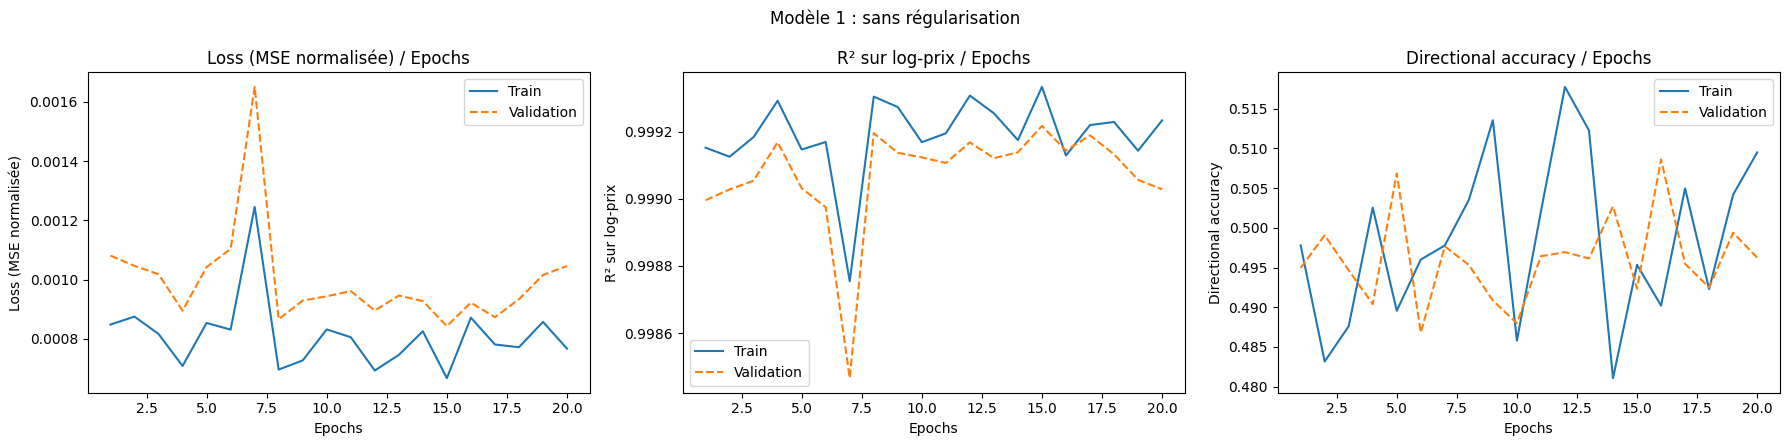

Naïf                         R² = 0.99934 | RMSE = 2.143 $ | Directional acc = 0.698%
1. Baseline (sans régularisation) R² = 0.99906 | RMSE = 5.275 $ | Directional acc = 50.826%
Epoch avec la meilleure loss de validation : 15


In [12]:
best = gs.best_params_
cfg = dict(hidden=best["module__hidden"], lr=best["lr"],
           optimizer=best["optimizer"].__name__.lower(),
           epochs=best["max_epochs"], batch_size=1024)
print("Config modèle 1 :", cfg)

model1, hist1 = train_model(**cfg)
plot_history(hist1, "Modèle 1 : sans régularisation", "images/modele1_courbes.png")

evaluate(cur_test, y_test, cur_test, "Naïf")
row1 = final_eval(model1, "1. Baseline (sans régularisation)")
print("Epoch avec la meilleure loss de validation :", hist1["best_ep"])

1. Baseline (sans reg.)      R² = 0.99906 | RMSE = 5.275 $ | Directional acc = 50.826%

--- 2. + Dropout (0.2) ---
2. + Dropout (0.2)           R² = 0.99406 | RMSE = 15.854 $ | Directional acc = 48.966%

--- 3. + L2 (weight decay) ---
3. + L2 (weight decay)       R² = 0.99916 | RMSE = 3.611 $ | Directional acc = 50.303%

--- 4. + BatchNorm ---
4. + BatchNorm               R² = 0.99652 | RMSE = 14.035 $ | Directional acc = 52.361%

--- 5. + Early stopping ---
Early stopping à l'epoch 13 (meilleure epoch : 8)
5. + Early stopping          R² = 0.99924 | RMSE = 2.984 $ | Directional acc = 49.596%

--- 6. Toutes combinées ---
Early stopping à l'epoch 10 (meilleure epoch : 5)
6. Toutes combinées          R² = 0.99805 | RMSE = 2.464 $ | Directional acc = 51.841%

--- 7. lr=0.001 (sans reg.) ---
7. lr=0.001 (sans reg.)      R² = 0.99927 | RMSE = 2.474 $ | Directional acc = 50.565%

--- 8. lr=0.001 + toutes ---
Early stopping à l'epoch 17 (meilleure epoch : 12)
8. lr=0.001 + toutes         R² =

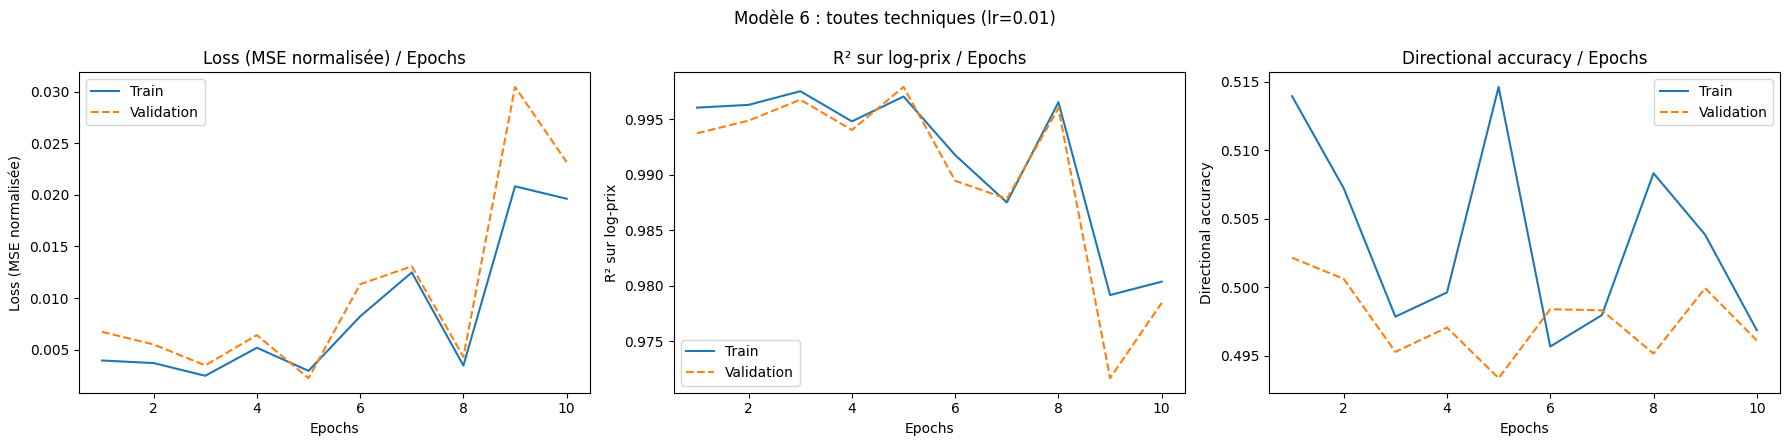

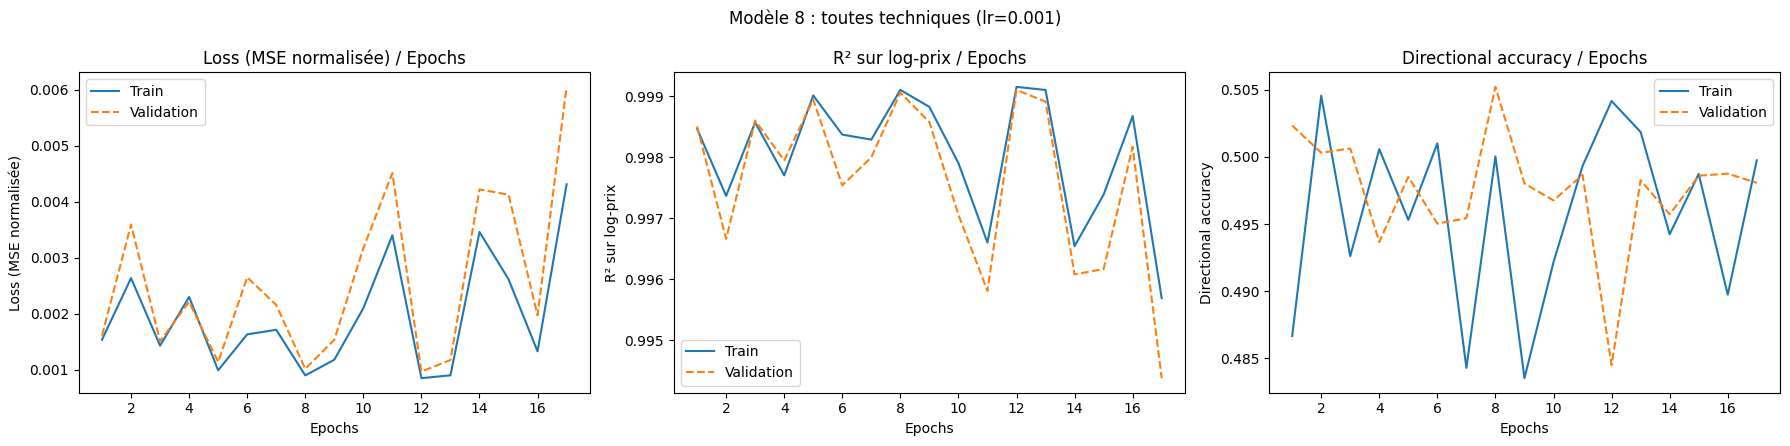

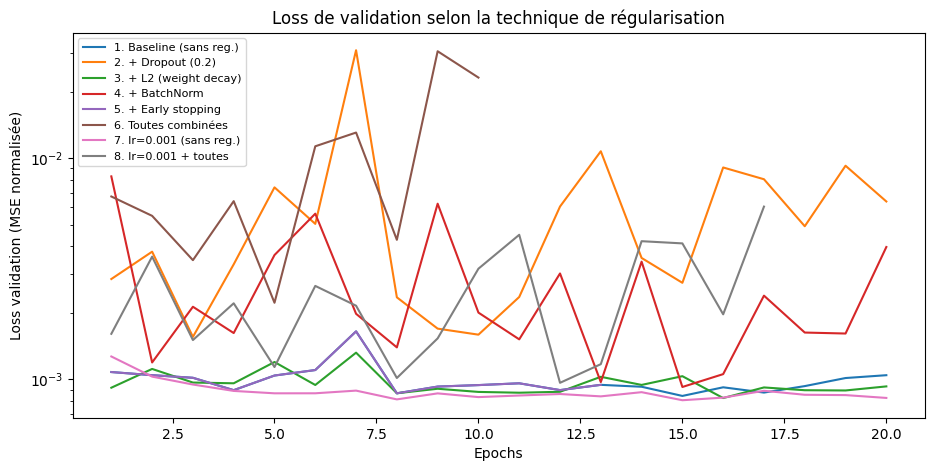

Note : les métriques du test sont calculées uniquement après l entraînement de chaque modèle.


In [13]:
configs = {
    "2. + Dropout (0.2)":      dict(dropout=0.2),
    "3. + L2 (weight decay)":  dict(weight_decay=1e-4),
    "4. + BatchNorm":          dict(batchnorm=True),
    "5. + Early stopping":     dict(patience=5),
    "6. Toutes combinées":     dict(dropout=0.2, weight_decay=1e-4, batchnorm=True, patience=5),
    "7. lr=0.001 (sans reg.)": dict(lr=1e-3),
    "8. lr=0.001 + toutes":    dict(lr=1e-3, dropout=0.2, weight_decay=1e-4, batchnorm=True, patience=5),
}

models = {"1. Baseline (sans reg.)": model1}
hists = {"1. Baseline (sans reg.)": hist1}
rows = [final_eval(model1, "1. Baseline (sans reg.)")]

for name, extra in configs.items():
    print(f"\n--- {name} ---")
    m, h = train_model(**{**cfg, **extra})
    models[name], hists[name] = m, h
    rows.append(final_eval(m, name))

# Ligne du baseline naïf (sans afficher une direction sans sens)
r2n = r2_score(y_test, cur_test)
rmsen = np.sqrt(np.mean((np.exp(cur_test) - np.exp(y_test)) ** 2))
rows.append({"Modèle": "Naïf (demain = aujourd'hui)", "R² test": r2n,
             "RMSE test ($)": rmsen, "Directional acc": np.nan})

results = pd.DataFrame(rows)
print("\n=== COMPARAISON FINALE (test 2016) ===")
print(results.to_string(index=False))
print("Référence direction : toujours hausse = 52.353%")
print("Meilleure epoch (validation) par modèle :",
      {k: v["best_ep"] for k, v in hists.items()})

# Courbes des 2 modèles combinés
plot_history(hists["6. Toutes combinées"], "Modèle 6 : toutes techniques (lr=0.01)",
             "images/modele6_courbes.png")
plot_history(hists["8. lr=0.001 + toutes"], "Modèle 8 : toutes techniques (lr=0.001)",
             "images/modele8_courbes.png")

# Comparaison des courbes de validation (le test n'est pas consulté à chaque époque)
plt.figure(figsize=(11, 5))
for name, h in hists.items():
    plt.plot(range(1, len(h["va_loss"]) + 1), h["va_loss"], label=name)
plt.xlabel("Epochs"); plt.ylabel("Loss validation (MSE normalisée)")
plt.title("Loss de validation selon la technique de régularisation")
plt.legend(fontsize=8); plt.yscale("log")
plt.savefig("images/comparaison_regularisation.png", dpi=150, bbox_inches="tight")
plt.show()

results.to_csv('results.csv', index=False)
print('Note : les métriques du test sont calculées uniquement après l entraînement de chaque modèle.')

In [14]:
import os
os.makedirs("images", exist_ok=True)
import matplotlib.pyplot as plt
_n = [0]
_show = plt.show
def show_and_save(*a, **k):
    _n[0] += 1
    plt.savefig(f"images/eda_{_n[0]:02d}.png", dpi=150, bbox_inches="tight")
    _show(*a, **k)
plt.show = show_and_save

=== PRICES ===
Shape : (851264, 7)
        date symbol        open       close         low        high     volume
0 2016-01-05   WLTW  123.430000  125.839996  122.309998  126.250000  2163600.0
1 2016-01-06   WLTW  125.239998  119.980003  119.940002  125.540001  2386400.0
2 2016-01-07   WLTW  116.379997  114.949997  114.930000  119.739998  2489500.0
3 2016-01-08   WLTW  115.480003  116.620003  113.500000  117.440002  2006300.0
4 2016-01-11   WLTW  117.010002  114.970001  114.089996  117.330002  1408600.0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 851264 entries, 0 to 851263
Data columns (total 7 columns):
 #   Column  Non-Null Count   Dtype         
---  ------  --------------   -----         
 0   date    851264 non-null  datetime64[ns]
 1   symbol  851264 non-null  object        
 2   open    851264 non-null  float64       
 3   close   851264 non-null  float64       
 4   low     851264 non-null  float64       
 5   high    851264 non-null  float64       
 6   volume  851264 n

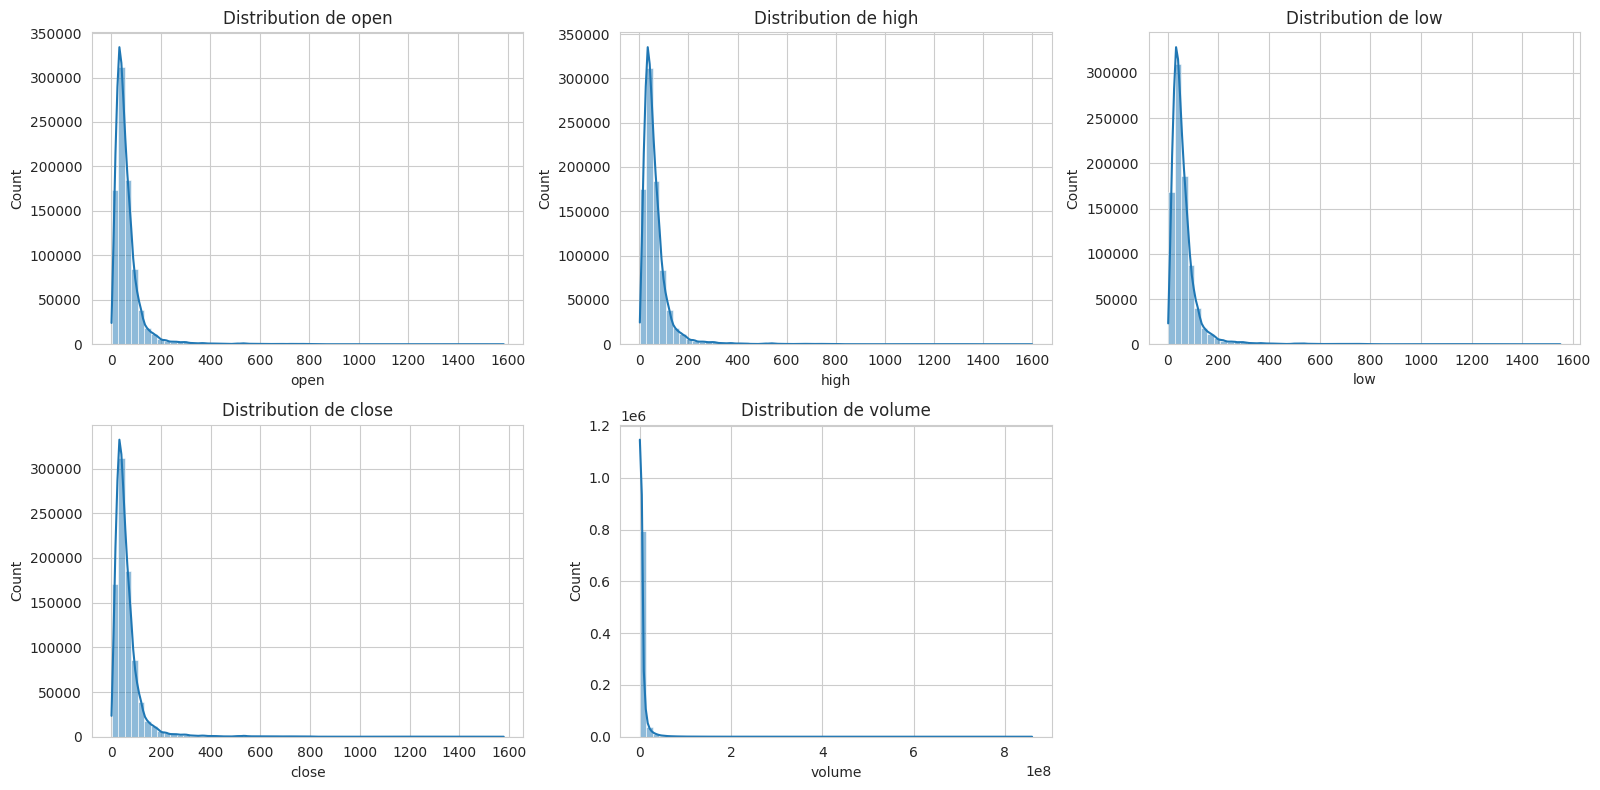

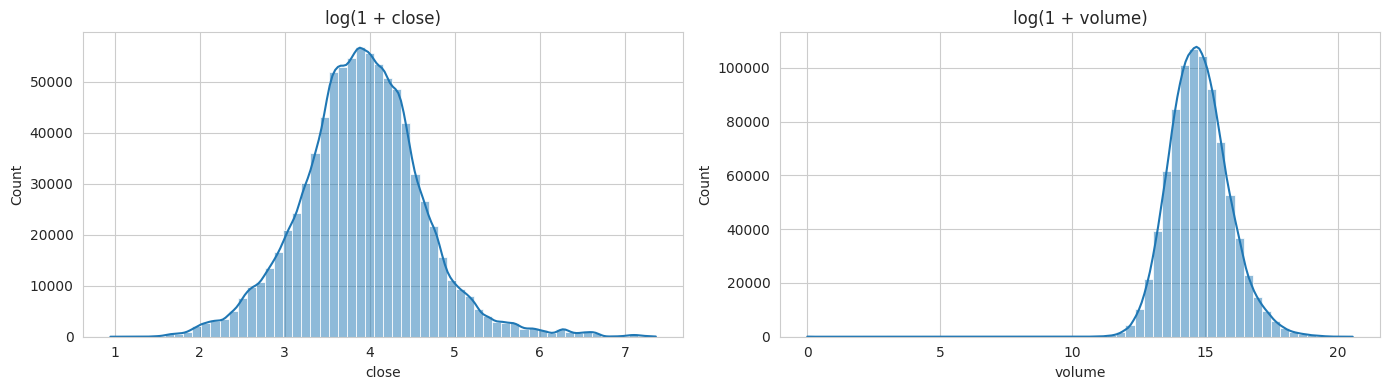

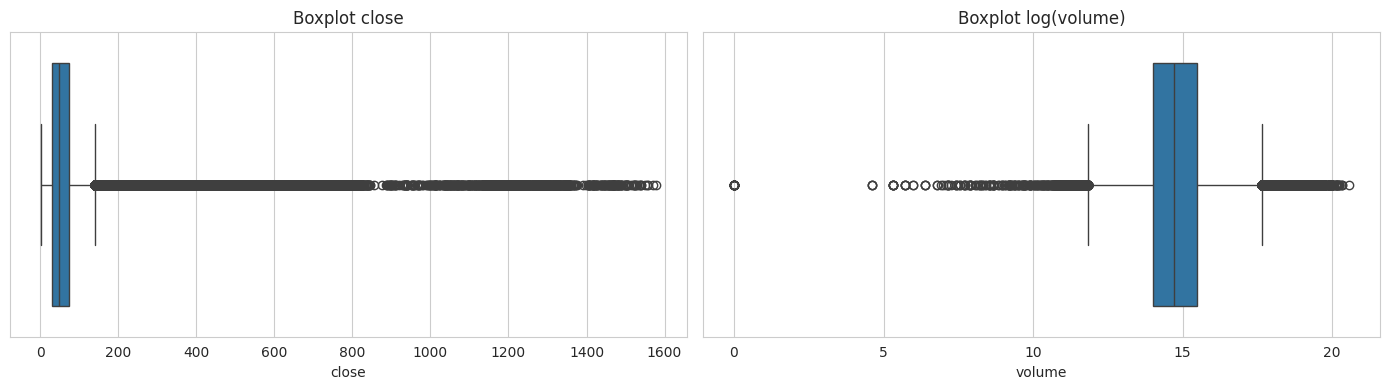

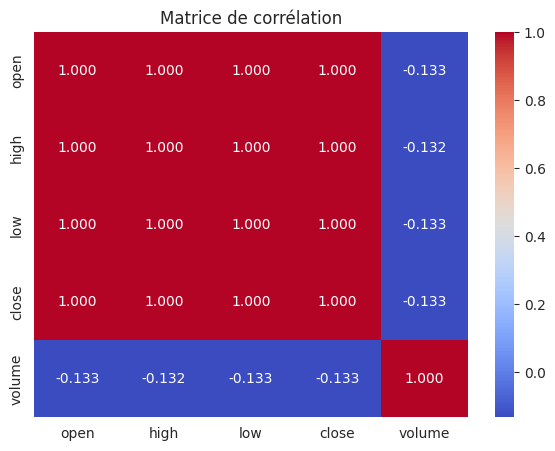

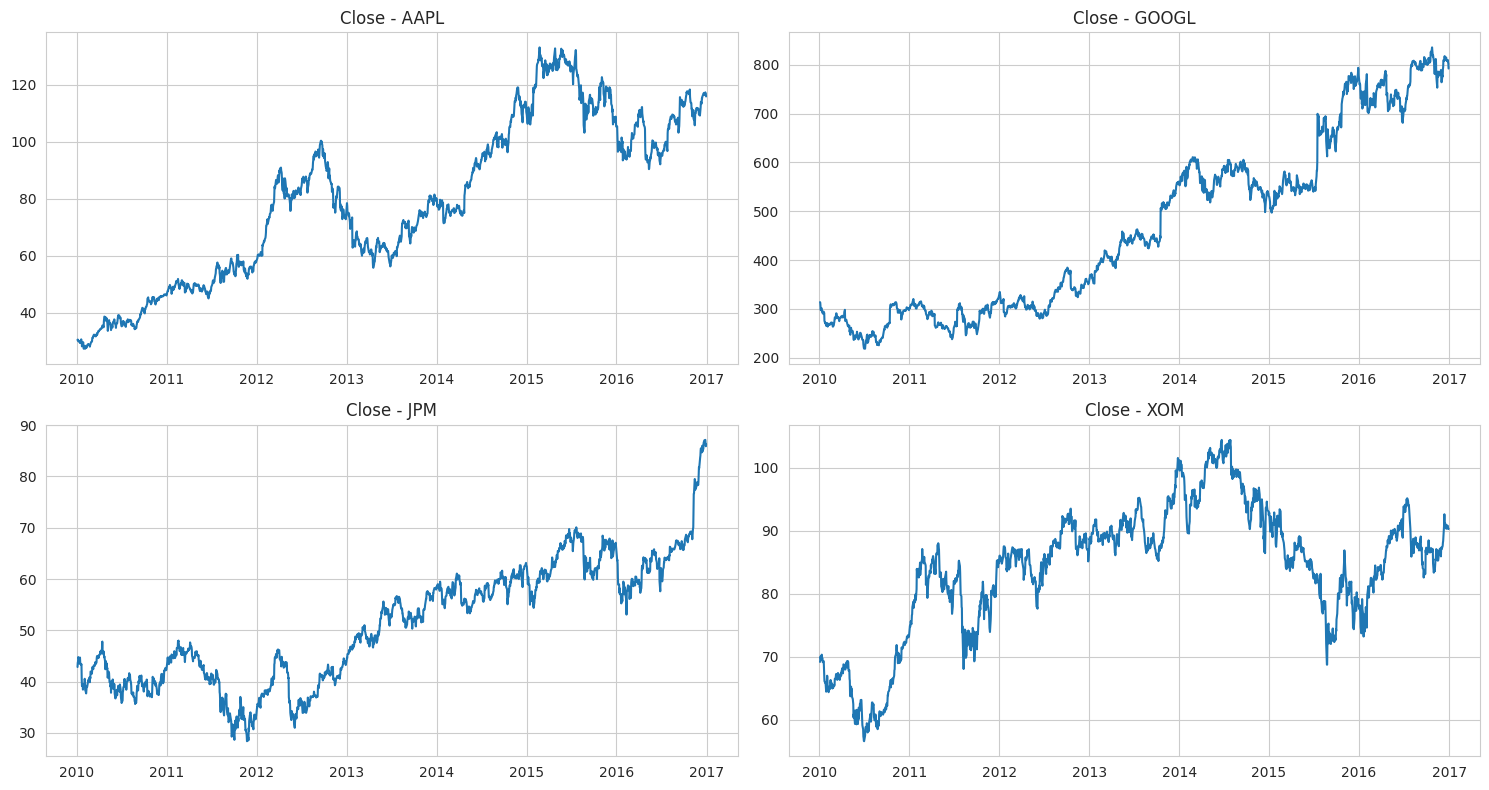

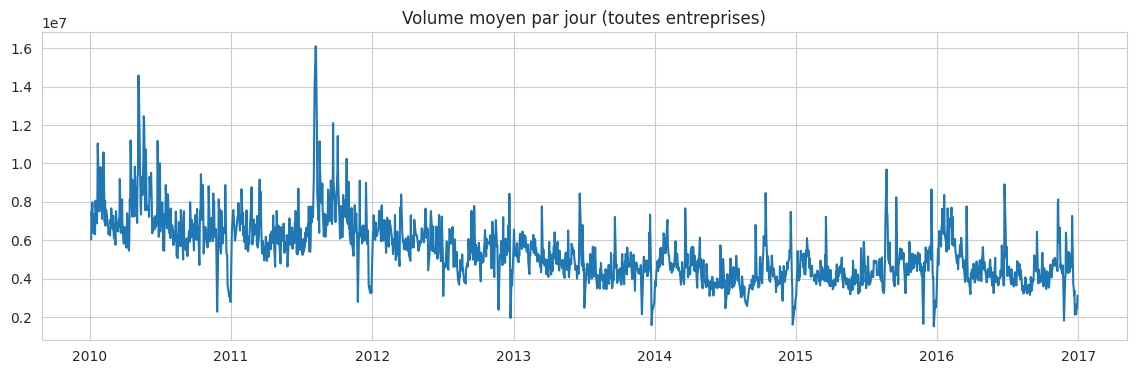

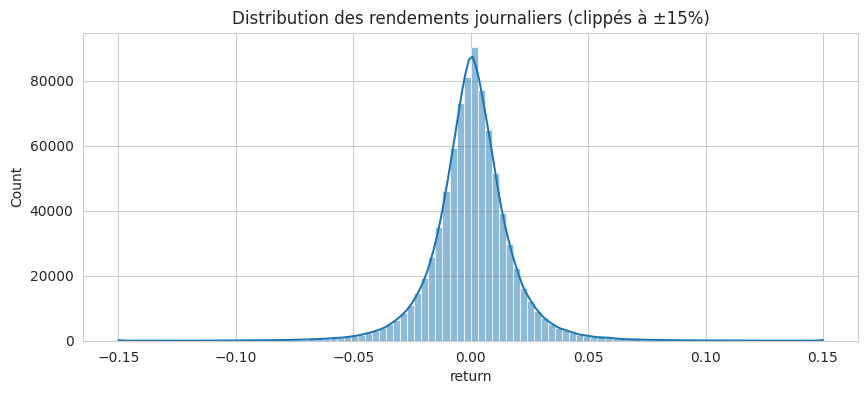

Rendement moyen : 0.0005923359900683787 | écart-type : 0.01812745001047994


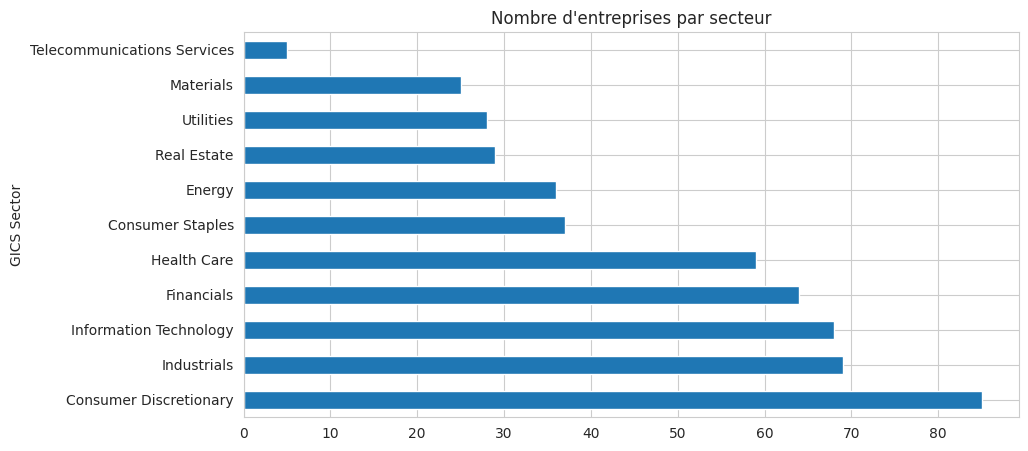

                                 mean       std
GICS Sector                                    
Consumer Discretionary       0.000681  0.018912
Consumer Staples             0.000570  0.013198
Energy                       0.000376  0.023063
Financials                   0.000571  0.017361
Health Care                  0.000707  0.018691
Industrials                  0.000652  0.018181
Information Technology       0.000656  0.019497
Materials                    0.000506  0.018570
Real Estate                  0.000542  0.015851
Telecommunications Services  0.000215  0.017813
Utilities                    0.000349  0.011979
                     count          mean           std           min  \
Total Revenue       1781.0  2.029154e+10  4.095355e+10  1.514000e+06   
Net Income          1781.0  1.705517e+09  3.993401e+09 -2.352800e+10   
Total Assets        1781.0  5.570921e+10  2.033590e+11  2.705000e+06   
Total Liabilities   1781.0  4.380420e+10  1.817039e+11  2.577000e+06   
Earnings Per Sha

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

# ---------- 1. Chargement ----------
prices = pd.read_csv("prices-split-adjusted.csv", parse_dates=["date"])
securities = pd.read_csv("securities.csv")
fundamentals = pd.read_csv("fundamentals.csv", index_col=0)

# ---------- 2. Vue d'ensemble ----------
print("=== PRICES ===")
print("Shape :", prices.shape)
print(prices.head())
print(prices.info())
print(prices.describe().T)
print("\nPériode :", prices["date"].min(), "->", prices["date"].max())
print("Nombre d'entreprises :", prices["symbol"].nunique())
print("Valeurs manquantes :\n", prices.isnull().sum())
print("Doublons :", prices.duplicated().sum())

print("\n=== SECURITIES ===")
print(securities.shape)
print(securities.head())

print("\n=== FUNDAMENTALS ===")
print(fundamentals.shape)
print("Colonnes avec le plus de NaN :")
print(fundamentals.isnull().sum().sort_values(ascending=False).head(10))

# ---------- 3. Nombre de jours par entreprise (données déséquilibrées ?) ----------
counts = prices.groupby("symbol").size()
print("\nJours par entreprise : min =", counts.min(), "| max =", counts.max())

# ---------- 4. Distribution des variables ----------
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), ["open", "high", "low", "close", "volume"]):
    sns.histplot(prices[col], bins=60, kde=True, ax=ax)
    ax.set_title(f"Distribution de {col}")
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

# Même chose en échelle log (les prix sont très asymétriques)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(np.log1p(prices["close"]), bins=60, kde=True, ax=axes[0])
axes[0].set_title("log(1 + close)")
sns.histplot(np.log1p(prices["volume"]), bins=60, kde=True, ax=axes[1])
axes[1].set_title("log(1 + volume)")
plt.tight_layout()
plt.show()

# ---------- 5. Outliers (boxplot) ----------
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(x=prices["close"], ax=axes[0]); axes[0].set_title("Boxplot close")
sns.boxplot(x=np.log1p(prices["volume"]), ax=axes[1]); axes[1].set_title("Boxplot log(volume)")
plt.tight_layout()
plt.show()

# ---------- 6. Corrélations ----------
plt.figure(figsize=(7, 5))
sns.heatmap(prices[["open", "high", "low", "close", "volume"]].corr(),
            annot=True, cmap="coolwarm", fmt=".3f")
plt.title("Matrice de corrélation")
plt.show()

# ---------- 7. Évolution temporelle de quelques actions ----------
symbols = ["AAPL", "GOOGL", "JPM", "XOM"]
fig, axes = plt.subplots(2, 2, figsize=(15, 8))
for ax, s in zip(axes.ravel(), symbols):
    d = prices[prices["symbol"] == s]
    if d.empty:
        ax.set_title(f"{s} absent"); continue
    ax.plot(d["date"], d["close"])
    ax.set_title(f"Close - {s}")
plt.tight_layout()
plt.show()

# ---------- 8. Volume moyen dans le temps ----------
vol_time = prices.groupby("date")["volume"].mean()
plt.figure(figsize=(14, 4))
plt.plot(vol_time)
plt.title("Volume moyen par jour (toutes entreprises)")
plt.show()

# ---------- 9. Rendements journaliers ----------
prices = prices.sort_values(["symbol", "date"])
prices["return"] = prices.groupby("symbol")["close"].pct_change()
plt.figure(figsize=(10, 4))
sns.histplot(prices["return"].dropna().clip(-0.15, 0.15), bins=100, kde=True)
plt.title("Distribution des rendements journaliers (clippés à ±15%)")
plt.show()
print("Rendement moyen :", prices["return"].mean(), "| écart-type :", prices["return"].std())

# ---------- 10. Secteurs ----------
plt.figure(figsize=(10, 5))
securities["GICS Sector"].value_counts().plot(kind="barh")
plt.title("Nombre d'entreprises par secteur")
plt.show()

# ---------- 11. Rendement moyen par secteur ----------
merged = prices.merge(securities[["Ticker symbol", "GICS Sector"]],
                      left_on="symbol", right_on="Ticker symbol", how="left")
sector_ret = merged.groupby("GICS Sector")["return"].agg(["mean", "std"])
print(sector_ret)

# ---------- 12. Fundamentals : quelques variables clés ----------
key = ["Total Revenue", "Net Income", "Total Assets", "Total Liabilities",
       "Earnings Per Share", "Profit Margin"]
key = [c for c in key if c in fundamentals.columns]
print(fundamentals[key].describe().T)

In [16]:
!zip -qr images.zip images
from google.colab import files
files.download("images.zip")
files.download("results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>